Calssication Project


In [1]:
import pandas as pd
import numpy as np
import pylab as pl
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
import matplotlib.pyplot as plt 
import scipy.optimize as opt

In [2]:
heart_df = pd.read_csv("heart.csv")
heart_df.head

<bound method NDFrame.head of      age  sex  cp  trtbps  chol  fbs  restecg  thalachh  exng  oldpeak  slp  \
0     63    1   3     145   233    1        0       150     0      2.3    0   
1     37    1   2     130   250    0        1       187     0      3.5    0   
2     41    0   1     130   204    0        0       172     0      1.4    2   
3     56    1   1     120   236    0        1       178     0      0.8    2   
4     57    0   0     120   354    0        1       163     1      0.6    2   
..   ...  ...  ..     ...   ...  ...      ...       ...   ...      ...  ...   
298   57    0   0     140   241    0        1       123     1      0.2    1   
299   45    1   3     110   264    0        1       132     0      1.2    1   
300   68    1   0     144   193    1        1       141     0      3.4    1   
301   57    1   0     130   131    0        1       115     1      1.2    1   
302   57    0   1     130   236    0        0       174     0      0.0    1   

     caa  thall  outp

In [3]:
heart_df.dtypes

age           int64
sex           int64
cp            int64
trtbps        int64
chol          int64
fbs           int64
restecg       int64
thalachh      int64
exng          int64
oldpeak     float64
slp           int64
caa           int64
thall         int64
output        int64
dtype: object

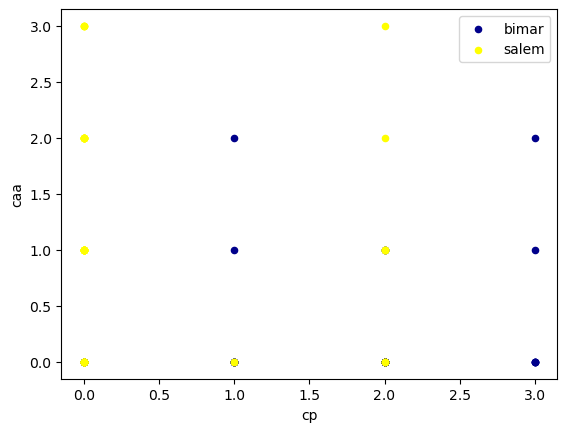

In [4]:
ax = heart_df[heart_df["output"]== 1][0:50].plot(kind='scatter', x='cp', y='caa', color='DarkBlue', label='bimar');
heart_df[heart_df["output"] == 0][0:50].plot(kind='scatter', x='cp', y='caa', color='Yellow', label='salem', ax=ax);
plt.show()

In [5]:
feature_df = heart_df[['age' , 'sex' , 'cp' , 'trtbps' , 'chol' , 'fbs' , 'restecg' , 'thalachh', 'exng','oldpeak','slp','caa', 'thall']] 
X = np.asarray(feature_df)
X[0:5]

array([[ 63. ,   1. ,   3. , 145. , 233. ,   1. ,   0. , 150. ,   0. ,
          2.3,   0. ,   0. ,   1. ],
       [ 37. ,   1. ,   2. , 130. , 250. ,   0. ,   1. , 187. ,   0. ,
          3.5,   0. ,   0. ,   2. ],
       [ 41. ,   0. ,   1. , 130. , 204. ,   0. ,   0. , 172. ,   0. ,
          1.4,   2. ,   0. ,   2. ],
       [ 56. ,   1. ,   1. , 120. , 236. ,   0. ,   1. , 178. ,   0. ,
          0.8,   2. ,   0. ,   2. ],
       [ 57. ,   0. ,   0. , 120. , 354. ,   0. ,   1. , 163. ,   1. ,
          0.6,   2. ,   0. ,   2. ]])

In [6]:
y = np.asarray(heart_df['output'])
y[0:5]

array([1, 1, 1, 1, 1])

In [7]:
X_train,X_test,y_train,y_test = train_test_split(X , y , test_size= 0.2 , random_state=4)
print("Train set" , X_train.shape , y_train.shape)
print("Test set" , X_test.shape , y_test.shape)

Train set (242, 13) (242,)
Test set (61, 13) (61,)


In [8]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Support Vector Machine

In [9]:
from sklearn import svm
clf = svm.SVC(kernel='rbf', class_weight='balanced')
clf.fit(X_train , y_train)

SVC(class_weight='balanced')

In [10]:
yhat = clf.predict(X_test)
yhat[0:5]

array([0, 0, 1, 1, 0])

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import itertools

In [12]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

              precision    recall  f1-score   support

           0       0.75      0.96      0.84        25
           1       0.97      0.78      0.86        36

    accuracy                           0.85        61
   macro avg       0.86      0.87      0.85        61
weighted avg       0.88      0.85      0.85        61

Confusion matrix, without normalization
[[24  1]
 [ 8 28]]
0.8535740359726556


np.float64(0.7272727272727273)

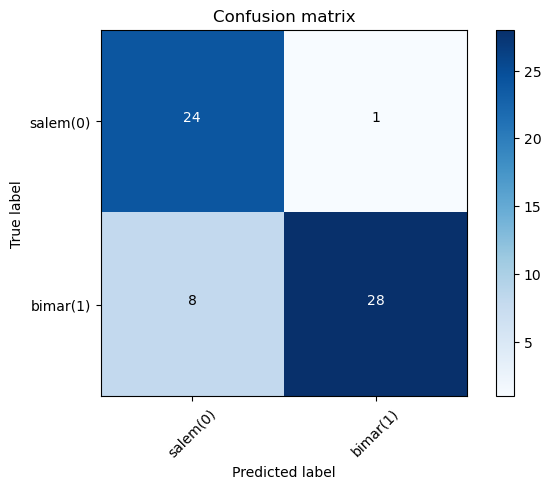

In [21]:
cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
np.set_printoptions(precision=2)

print (classification_report(y_test, yhat))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=['salem(0)','bimar(1)'],normalize= False,  title='Confusion matrix')


from sklearn.metrics import f1_score
f1_score_svm = f1_score(y_test , yhat , average='weighted')
print(f1_score_svm)

from sklearn.metrics import jaccard_score
jaccard_score(y_test , yhat , pos_label=0)

# KNN

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, jaccard_score

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

yhat_knn = knn.predict(X_test)

print(classification_report(y_test, yhat_knn))

print("F1 Score:",
      f1_score(y_test, yhat_knn, average='weighted'))

print("Jaccard Score:",
      jaccard_score(y_test, yhat_knn))

              precision    recall  f1-score   support

           0       0.74      0.80      0.77        25
           1       0.85      0.81      0.83        36

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.81      0.80      0.80        61

F1 Score: 0.8042514862186994
Jaccard Score: 0.7073170731707317


In [15]:
from sklearn.metrics import confusion_matrix

yhat_knn = knn.predict(X_test)

cm_knn = confusion_matrix(y_test, yhat_knn)
print("Confusion Matrix KNN")
print(cm_knn)

Confusion Matrix KNN
[[20  5]
 [ 7 29]]


# Logistic Regression

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, jaccard_score

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train, y_train)

yhat_lr = lr.predict(X_test)

print(classification_report(y_test, yhat_lr))

print("F1 Score:",
      f1_score(y_test, yhat_lr, average='weighted'))

print("Jaccard Score:",
      jaccard_score(y_test, yhat_lr))

              precision    recall  f1-score   support

           0       0.81      0.88      0.85        25
           1       0.91      0.86      0.89        36

    accuracy                           0.87        61
   macro avg       0.86      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61

F1 Score: 0.8695009908124662
Jaccard Score: 0.7948717948717948


In [17]:
yhat_lr = lr.predict(X_test)

cm_lr = confusion_matrix(y_test, yhat_lr)
print("Confusion Matrix Logistic Regression")
print(cm_lr)

Confusion Matrix Logistic Regression
[[22  3]
 [ 5 31]]


# Decision Tree

In [18]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, f1_score, jaccard_score

tree = DecisionTreeClassifier(criterion='entropy', max_depth=4)

tree.fit(X_train, y_train)

yhat_tree = tree.predict(X_test)

print(classification_report(y_test, yhat_tree))

print("F1 Score:",
      f1_score(y_test, yhat_tree, average='weighted'))

print("Jaccard Score:",
      jaccard_score(y_test, yhat_tree))

              precision    recall  f1-score   support

           0       0.86      0.76      0.81        25
           1       0.85      0.92      0.88        36

    accuracy                           0.85        61
   macro avg       0.85      0.84      0.84        61
weighted avg       0.85      0.85      0.85        61

F1 Score: 0.8507010812696197
Jaccard Score: 0.7857142857142857


In [19]:
yhat_tree = tree.predict(X_test)

cm_tree = confusion_matrix(y_test, yhat_tree)
print("Confusion Matrix Decision Tree")
print(cm_tree)

Confusion Matrix Decision Tree
[[19  6]
 [ 3 33]]


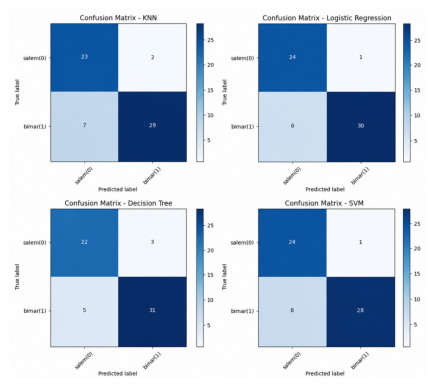

In [20]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread('confusion_matrix_knn.png')
plt.imshow(img)
plt.axis('off')
plt.show()